## Import packages

In [1]:
!pip install sdv pandas ipykernel

In [ ]:
import sdv
import pandas as pd

## Load local dataset

In [ ]:
from sdv.io.local import CSVHandler

connector = CSVHandler()
real_data = connector.read(
    folder_name='data',
    file_names=['hotel_guests_data.csv'])

In [ ]:
real_data["hotel_guests_data"].head(10)

,guest_email,has_rewards,room_type,amenities_fee,checkin_date,checkout_date,room_rate,billing_address,credit_card_number
0,dsullivan@example.net,False,BASIC,8.324971,04 Apr 2020,23 Apr 2020,146.834507,"90469 Karla Knolls Apt. 781\nSusanberg, NC 28401",5161033759518983
1,steven59@example.org,False,BASIC,NaN,27 Jun 2020,16 Aug 2020,185.497813,"1080 Ashley Creek Apt. 622\nWest Amy, NM 25058",4133047413145475690
2,brandon15@example.net,False,BASIC,22.269158,13 Apr 2020,07 Apr 2020,151.115528,"99923 Anderson Trace Suite 861\nNorth Haley, T...",4977328103788
3,humphreyjennifer@example.net,False,BASIC,25.468647,22 May 2020,08 Jun 2020,182.468031,"9301 John Parkways\nThomasland, OH 61350",3524946844839485
4,joshuabrown@example.net,False,BASIC,19.778311,14 Nov 2019,27 Oct 2019,195.497743,"126 George Tunnel\nDuranstad, MS 95176",4446905799576890978
5,moondavid@example.com,False,BASIC,NaN,30 Oct 2020,17 Nov 2020,88.247232,"812 Kimberly Forges\nEast Brianafurt, AR 16834",4265310195602383
6,patty61@example.com,False,BASIC,16.670851,07 Oct 2020,30 Aug 2020,83.800000,7999 Sheila Forges Apt. 089\nWest Briannahaven...,30279530784085
7,michellehill@example.net,False,SUITE,13.991605,01 Sep 2020,28 Aug 2020,204.266982,79445 Brandon Plains Apt. 024\nPort Cynthiapor...,2285102384715773
8,loganosborne@example.org,False,BASIC,18.410008,09 Sep 2020,04 Sep 2020,128.384707,"522 Davis Street\nNew Cole, AZ 17369",3541571714584497
9,gkey@example.org,False,BASIC,27.616677,20 Oct 2020,22 Nov 2020,217.617926,"77972 Wendy Lake Apt. 933\nKelseyhaven, WI 35555",676377598427


## Detect metadata

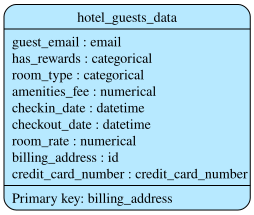

In [ ]:
from sdv.metadata import Metadata

# Create metadata via auto-detection (if you don't already have it)
metadata = Metadata.detect_from_dataframes(real_data)

# Carefully inspect and update your metadata
metadata.visualize()

In [2]:
# Update metadata if necessary (in this case, I needed to update the billing_address column from 'id' type to 'address')
metadata.update_column(
    column_name='billing_address',
    sdtype='address',
    table_name='hotel_guests_data'
)
metadata.validate()

# When you're done, save it to a file for future use
metadata.save_to_json('data/_metadata.json')


KeyboardInterrupt



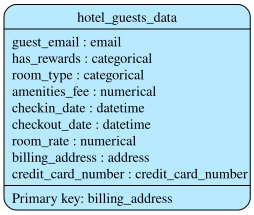

In [ ]:
metadata.visualize()

## Create synthetic data

In [ ]:
from sdv.single_table import GaussianCopulaSynthesizer

synthesizer = GaussianCopulaSynthesizer(metadata)
synthesizer.fit(real_data)

synthetic_data = synthesizer.sample(num_rows=100)

In [ ]:
synthetic_data['hotel_guests_data']

,guest_email,has_rewards,room_type,amenities_fee,checkin_date,checkout_date,room_rate,billing_address,credit_card_number
0,alan63@example.net,False,BASIC,5.638889,22 Mar 2020,19 Apr 2020,88.572152,"PSC 5143, Box 0674\nAPO AP 09723",4529984219396740110
1,rayscott@example.org,False,BASIC,17.941228,16 Jun 2020,20 Aug 2020,117.148659,"8154 Darryl Roads Apt. 237\nEast Rickyview, WA...",584374818188
2,rward@example.com,False,BASIC,18.155098,18 Apr 2020,07 Apr 2020,102.027522,"072 Diaz Plaza Suite 959\nNew Jenniferfort, DC...",2298237002279409
3,christopherwong@example.com,False,BASIC,34.555410,21 May 2020,11 Jun 2020,84.719449,"21168 Winters Neck Suite 438\nSmithshire, MN 8...",3564807725421606
4,thomaskrueger@example.net,False,BASIC,19.970559,18 Nov 2019,25 Oct 2019,144.304703,"2357 Katrina Tunnel Suite 648\nMatthewstad, LA...",4912835132632
...,...,...,...,...,...,...,...,...,...
95,tanyahorn@example.net,True,BASIC,8.847072,24 Jul 2020,21 Jun 2020,89.333960,"79179 Smith Locks\nRangelmouth, WV 80561",4773995913421
96,whitezachary@example.net,False,BASIC,21.060211,13 Oct 2020,27 Sep 2020,107.920434,"PSC 3904, Box 8507\nAPO AP 72714",3552483524856634
97,timothy74@example.org,False,BASIC,37.807783,05 May 2020,17 Mar 2020,87.431485,"553 Charles Fork Apt. 039\nGinashire, OH 33078",4840637315408216
98,emma87@example.org,False,BASIC,16.047596,04 Dec 2020,25 Dec 2020,89.468902,"000 Juan Plain Apt. 330\nJenniferview, MD 69466",675981873440


In [ ]:
synthetic_data['hotel_guests_data'].to_csv("data/hotel_guests_data_synthetic.csv", index=False)

## ⚠️ Final checks:
Synthetic data doesn't mean data is 100% anonymous. There might still be some sensitive information that can be derived from the metadata or the synthetic records. 

Therefore, it's recommended to make sure this dataset is safe to share online. Pro tip: Use minimum data needed for your analysis - if a column is redundant, just remove it!